# Chronos LoRA: EOS loss 제외 · best checkpoint · 학습률 3개 비교

**현재 프로토콜:** 평가 배터리를 제외한 세 배터리에서 시간순 train/validation을 나눕니다. 입력 EOS는 유지하고 출력 EOS loss만 제외합니다. 학습률 `1e-5`, `3e-5`, `1e-4` 각각 최대 100 optimizer steps를 학습하며, 10 steps마다 validation CRPS를 계산합니다. Validation을 학습에 합치는 **full-data refit은 하지 않습니다.**

각 후보의 best checkpoint를 저장하고 validation CRPS로 학습률을 선택합니다. Step 0도 후보입니다. 네 fold의 선택을 모두 고정한 후 저장된 adapter를 재로딩해 held-out 배터리를 평가합니다. 세 학습률은 Optuna 없이 모두 비교합니다.

R²는 중앙값·평균 예측에 각각 계산합니다. 배터리·seed별 전체 window/horizon을 펼쳐 `1 - SSE/SST`를 구하고 배터리를 동일 가중치로 평균합니다. 1은 완벽한 예측, 0은 평가 target 평균을 항상 예측한 수준이며 음수도 가능합니다. 상수 target은 NaN입니다. 짧은 validation/window는 target 변동이 작아 R²가 크게 낮아질 수 있습니다. R²는 보고용이며 학습률·checkpoint 선택 기준은 CRPS로 유지합니다.

학습 seed는 42, validation seed는 31415/31416/31417(각 32 samples), 최종 추론 seed는 42/43/44(각 100 samples)입니다. 추론 반복과 학습 반복은 다릅니다. 04 Full FT는 여기서 실행하지 않습니다.

마지막 절의 2026-09-29 EOS 진단은 **과거 full-data 학습 결과**이며, 이 새 프로토콜과 구분합니다. [프로토콜](../docs/lora_checkpoint_protocol.md) · [현재 결과 보고서](../results/checkpoint_lora/report.md)

In [1]:
from pathlib import Path
import sys

# Works with the kernel started from the project root or notebooks/.
PROJECT_ROOT = next(
    p for p in (Path.cwd().resolve(), *Path.cwd().resolve().parents)
    if (p / "data" / "raw").is_dir() and (p / "src" / "soh_experiment.py").is_file()
)
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

import json
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from src.soh_experiment import (
    load_config, load_soh, make_windows, temporal_split,
    find_zeroshot, find_lobo, run_zeroshot, run_lobo, verify_saved_run,
)
from src.soh_plots import forecast_grid, horizon_comparison, validation_curves, window_comparison
from src.soh_evaluation import export_run, export_diagnosis, evaluation_directory

CONFIG = load_config(PROJECT_ROOT)
FORCE_RERUN = False  # True: new run directory; False: reuse only verified compatible artifacts.
print("Project:", PROJECT_ROOT)
print(CONFIG)

from src.soh_checkpoint import (
    load_checkpoint_config, find_checkpoint_run, run_checkpoint_search, verify_checkpoint_run,
)
CONFIG, CHECKPOINT_POLICY = load_checkpoint_config(PROJECT_ROOT)
print("Current LoRA policy:", CHECKPOINT_POLICY)


Project: C:\Users\dbsgh\Desktop\Lab\chronos-battery-soh
ExperimentConfig(model_id='amazon/chronos-t5-base', revision='ad294eaacead15db499b740ea4122266dd2a81a2', battery_ids=('B0005', 'B0006', 'B0007', 'B0018'), context_length=64, prediction_length=16, device='auto', inference_batch_size=16, num_samples=100, inference_seeds=(42, 43, 44), temperature=1.0, top_k=50, top_p=1.0, train_seeds=(42,), batch_size=16, learning_rate=0.0001, weight_decay=0.0, lora_rank=8, lora_alpha=16, lora_dropout=0.05, max_epochs=10, validation_fraction=0.2, validation_samples=32, validation_seed=31415, patience=3, min_delta=1e-05)
Current LoRA policy: CheckpointPolicy(learning_rates=(1e-05, 3e-05, 0.0001), max_steps=100, eval_every_steps=10, validation_samples=32, validation_seeds=(31415, 31416, 31417), min_delta=1e-05)


## 학습·검증·평가 배터리 구분

평가 배터리 1개는 학습률과 step 선택에 사용하지 않습니다. 나머지 세 배터리의 뒤쪽 20% target은 validation으로 남기며, target이 경계에 걸친 window는 제외합니다. Validation의 context는 해당 시점까지 실제 관측된 과거입니다.

In [2]:
soh_data = load_soh(PROJECT_ROOT, CONFIG)
split_rows = []
for battery, series in soh_data.items():
    training, validation, cutoff = temporal_split(series, CONFIG)
    split_rows.append({
        "battery": battery, "train_windows": len(training["target"]),
        "validation_windows": len(validation["target"]),
        "train_target_last_cycle": int(training["forecast_start"][-1] + CONFIG.prediction_length - 1),
        "validation_target_first_cycle": int(validation["forecast_start"][0]),
    })
display(pd.DataFrame(split_rows))
display(pd.DataFrame([{"test": b, "train/validation batteries": ", ".join(x for x in CONFIG.battery_ids if x != b)} for b in CONFIG.battery_ids]))

,battery,train_windows,validation_windows,train_target_last_cycle,validation_target_first_cycle
0,B0005,55,19,134,135
1,B0006,55,19,134,135
2,B0007,55,19,134,135
3,B0018,26,12,105,106


,test,train/validation batteries
0,B0005,"B0006, B0007, B0018"
1,B0006,"B0005, B0007, B0018"
2,B0007,"B0005, B0006, B0018"
3,B0018,"B0005, B0006, B0007"


## 12개 후보 학습과 best checkpoint 평가

완료된 동일 실행은 소스·데이터·설정·산출물 해시 및 원시 예측 지표를 검산한 뒤 재사용합니다. 호환되는 실행이 없으면 3개 학습률 × 4개 fold를 실행합니다. `FORCE_RERUN=True`는 새 프로토콜의 전체 탐색을 다시 실행합니다.

각 후보는 같은 초기화와 minibatch 순서로 학습합니다. 검증 난수는 학습 상태를 바꾸지 않습니다. CRPS가 `min_delta=1e-5`보다 크게 개선될 때만 checkpoint를 교체하며, 유사한 점수에서는 앞선 step/학습률을 유지합니다.

In [3]:
CHECKPOINT_RUN = None if FORCE_RERUN else find_checkpoint_run(PROJECT_ROOT, CONFIG, CHECKPOINT_POLICY)
CHECKPOINT_RUN = CHECKPOINT_RUN or run_checkpoint_search(PROJECT_ROOT, CONFIG, CHECKPOINT_POLICY)
manifest = json.loads((CHECKPOINT_RUN / "manifest.json").read_text(encoding="utf-8"))
ZERO_RUN = Path(manifest["zeroshot_run"])
print("Current LoRA run:", CHECKPOINT_RUN)
print("Zero-shot reference:", ZERO_RUN)
display(verify_checkpoint_run(CHECKPOINT_RUN, PROJECT_ROOT, CONFIG, CHECKPOINT_POLICY))
CHECKPOINT_EVAL = export_run(PROJECT_ROOT, CHECKPOINT_RUN)
ZERO_EVAL = evaluation_directory(PROJECT_ROOT, ZERO_RUN)

Current LoRA run: C:\Users\dbsgh\Desktop\Lab\chronos-battery-soh\results\runs\20260929T175636Z_checkpointlora_39b551
Zero-shot reference: C:\Users\dbsgh\Desktop\Lab\chronos-nasa-soh\results\runs\20260923T063348Z_zeroshot_b57856


{'run_id': '20260929T175636Z_checkpointlora_39b551',
 'metric_rows_verified': 24,
 'artifacts_verified': 193,
 'status': 'passed',
 'distribution_rows_verified': 24,
 'trial_count': 12}

## Validation으로 선택한 학습률과 step

아래 CRPS는 test 점수가 아니라 학습 배터리의 validation 점수입니다. 세 validation seed의 sample을 합치지 않고 각 seed의 점수를 먼저 계산한 뒤 평균합니다. `selected_step`은 실제로 평가할 저장 checkpoint의 시점, `executed_steps`는 후보 학습을 탐색한 총 횟수입니다.

,test_battery,train_seed,learning_rate,selected_step,executed_steps,validation_crps
0,B0005,42,0.0001,100,100,0.006842
1,B0006,42,0.0001,90,100,0.006575
2,B0007,42,0.0001,90,100,0.006998
3,B0018,42,0.0001,80,100,0.005106


,test_battery,train_seed,learning_rate,selected_step,median_rmse,median_mae,mean_rmse,crps,coverage80,width80,negative_rate,above2_rate,median_r2,mean_r2
0,B0005,42,0.00001,100,0.013383,0.009638,0.013611,0.007528,0.765899,0.036147,0.0,0.0,-0.181257,-0.215617
1,B0005,42,0.00003,100,0.013234,0.009634,0.013325,0.007459,0.754630,0.035278,0.0,0.0,-0.169492,-0.170732
2,B0005,42,0.00010,100,0.012361,0.009319,0.011803,0.006842,0.683967,0.027127,0.0,0.0,-0.030270,0.128117
3,B0006,42,0.00001,50,0.012324,0.008890,0.012582,0.007038,0.809180,0.035931,0.0,0.0,-0.327632,-0.387758
4,B0006,42,0.00003,100,0.012343,0.009024,0.012440,0.007021,0.798154,0.034861,0.0,0.0,-0.332114,-0.354972
5,B0006,42,0.00010,90,0.011971,0.008967,0.010984,0.006575,0.701937,0.026590,0.0,0.0,-0.256906,-0.052959
6,B0007,42,0.00001,90,0.013495,0.009689,0.013708,0.007614,0.786732,0.037168,0.0,0.0,-0.159221,-0.187835
7,B0007,42,0.00003,100,0.013378,0.009707,0.013537,0.007549,0.773666,0.035928,0.0,0.0,-0.158150,-0.169341
8,B0007,42,0.00010,90,0.012651,0.009388,0.011969,0.006998,0.681652,0.027393,0.0,0.0,-0.084984,0.101270
9,B0018,42,0.00001,10,0.009824,0.007530,0.010285,0.005509,0.751827,0.023139,0.0,0.0,0.255780,0.171538


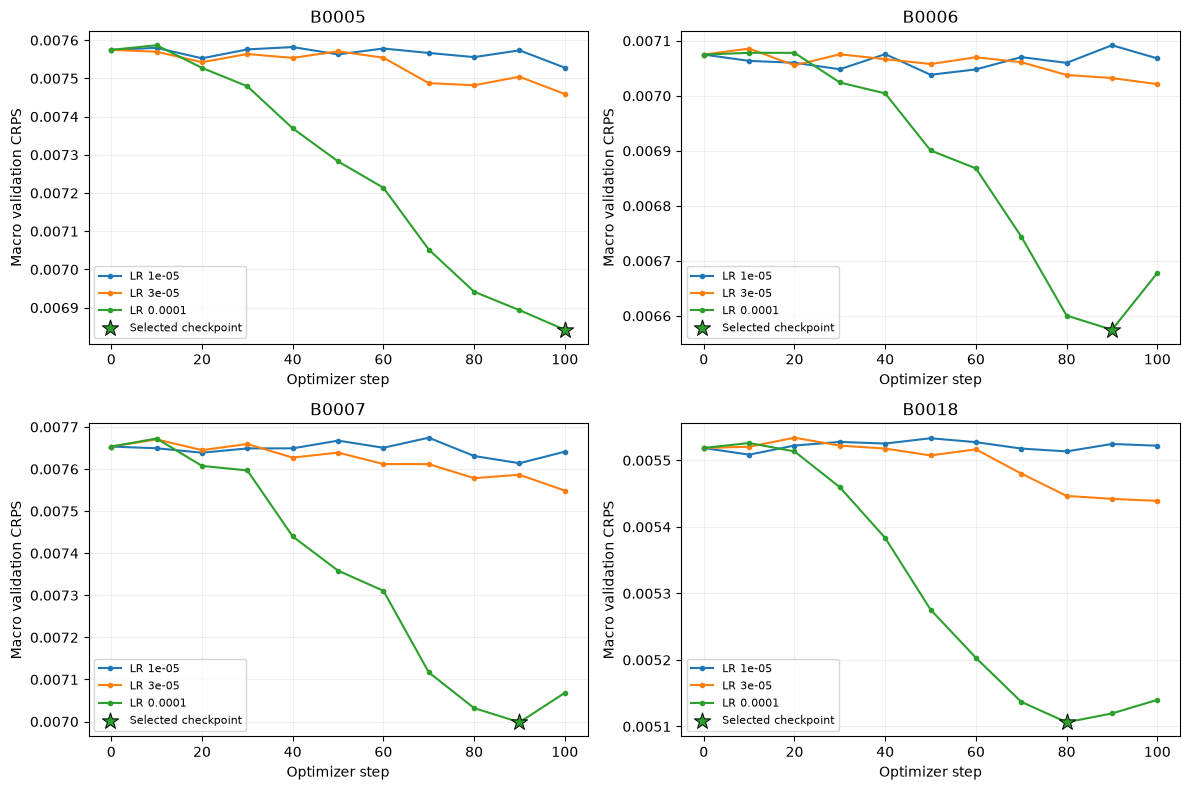

In [4]:
display(pd.DataFrame([
    {"test_battery": fold["test_battery"], "train_seed": fold["train_seed"],
     "learning_rate": fold["learning_rate"], "selected_step": fold["selected_step"],
     "executed_steps": fold["executed_steps"],
     "validation_crps": fold["selected_validation"]["macro"]["crps"]}
    for fold in manifest["folds"]
]))
display(pd.read_csv(CHECKPOINT_EVAL / "validation_candidates.csv").drop(columns="trial_path"))
from scripts.summarize_checkpoint_lora import plot_learning_curves
plot_learning_curves(CHECKPOINT_RUN)
plt.show()

## 같은 조건의 zero-shot과 비교

학습률·checkpoint 선택이 끝난 후 생성한 held-out 예측입니다. 표는 seed별 점수를 평균한 뒤 배터리에 같은 가중치를 줍니다. `mean_rmse`는 sample mean을 점예측으로 사용한 오차입니다. `coverage80`과 이상 sample 비율은 0~1 단위입니다.

In [5]:
current_scores = pd.read_csv(CHECKPOINT_EVAL / "distribution_metrics.csv")
score_columns = ["median_rmse", "median_mae", "median_r2", "mean_rmse", "mean_r2", "crps", "coverage80", "width80", "above2_rate"]
current_battery = current_scores.groupby(["model", "battery"])[score_columns].mean()
current_macro = current_battery.groupby(level="model").mean().loc[["ZeroShot", "SelectedLoRA"]]
display(current_macro.round(6))
display(current_battery.round(6))
print("Zero-shot 대비 오차 감소율 (%; 양수=개선)")
display((100 * (1 - current_macro.loc["SelectedLoRA", ["median_rmse", "mean_rmse", "crps"]]
                / current_macro.loc["ZeroShot", ["median_rmse", "mean_rmse", "crps"]])).round(3))
print("R² change (absolute difference; higher is better)")
display((current_macro.loc["SelectedLoRA", ["median_r2", "mean_r2"]] - current_macro.loc["ZeroShot", ["median_r2", "mean_r2"]]).round(6))
display(pd.read_csv(CHECKPOINT_EVAL / "paired_macro.csv"))

,median_rmse,median_mae,median_r2,mean_rmse,mean_r2,crps,coverage80,width80,above2_rate
model,,,,,,,,,
ZeroShot,0.016307,0.011607,0.676844,0.018540,0.616669,0.008769,0.803182,0.042410,0.000063
SelectedLoRA,0.014355,0.009920,0.733519,0.015202,0.705528,0.007461,0.765325,0.033405,0.000028


median_rmse  median_mae  median_r2  mean_rmse   mean_r2  \
model        battery                                                            
SelectedLoRA B0005       0.009637    0.006696   0.963486   0.009980  0.960823   
             B0006       0.017375    0.011246   0.869341   0.017757  0.863525   
             B0007       0.009932    0.006545   0.932077   0.011790  0.904131   
             B0018       0.020476    0.015193   0.169170   0.021282  0.093633   
ZeroShot     B0005       0.012601    0.009050   0.937543   0.013980  0.923080   
             B0006       0.018900    0.012889   0.845382   0.020228  0.822900   
             B0007       0.011423    0.007927   0.910154   0.016665  0.800628   
             B0018       0.022303    0.016563   0.014299   0.023288 -0.079932   

                          crps  coverage80   width80  above2_rate  
model        battery                                               
SelectedLoRA B0005    0.005104    0.748361  0.021484     0.000005  
             B0006    0.008481    0.764045  0.035962     0.000007  
             B0007    0.005014    0.688436  0.017828     0.000047  
             B0018    0.011245    0.860456  0.058349     0.000055  
ZeroShot     B0005    0.006828    0.812968  0.034216     0.000054  
             B0006    0.009832    0.766386  0.043659     0.000023  
             B0007    0.005939    0.807116  0.029546     0.000105  
             B0018    0.012478    0.826258  0.062221     0.000071

Zero-shot 대비 오차 감소율 (%; 양수=개선)


median_rmse    11.969
mean_rmse      18.003
crps           14.917
dtype: float64

R² change (absolute difference; higher is better)


median_r2    0.056674
mean_r2      0.088859
dtype: float64

,train_seed,inference_seed,estimator,rmse_lora,rmse_zero,mae_lora,mae_zero,r2_lora,r2_zero,rmse_improvement,mae_improvement,r2_improvement,rmse_improvement_pct
0,42,42,mean,0.014879,0.017435,0.010364,0.012020,0.737264,0.664866,0.002556,0.001655,0.072398,14.657908
1,42,42,median,0.014370,0.016251,0.009939,0.011556,0.731639,0.676156,0.001881,0.001617,0.055484,11.572556
2,42,43,mean,0.014734,0.017970,0.010254,0.012224,0.740316,0.651591,0.003236,0.001969,0.088725,18.009834
3,42,43,median,0.014415,0.016482,0.009919,0.011639,0.731114,0.670644,0.002068,0.001720,0.060471,12.544989
4,42,44,mean,0.015994,0.020216,0.010818,0.012876,0.639003,0.533549,0.004221,0.002057,0.105454,20.881595
5,42,44,median,0.014280,0.016187,0.009901,0.011626,0.737802,0.683734,0.001907,0.001725,0.054068,11.780629


## 선택 checkpoint의 SOH 곡선

각 배터리의 첫·중간·마지막 window를 선택했습니다. 과거 관측 64개로 미래 16개를 예측하며, 평활화나 clipping 없이 예측 중앙값과 10~90% 구간을 표시합니다. 추론 seed 42의 예시이며 전체 결과는 위의 세 seed 평가 표입니다.

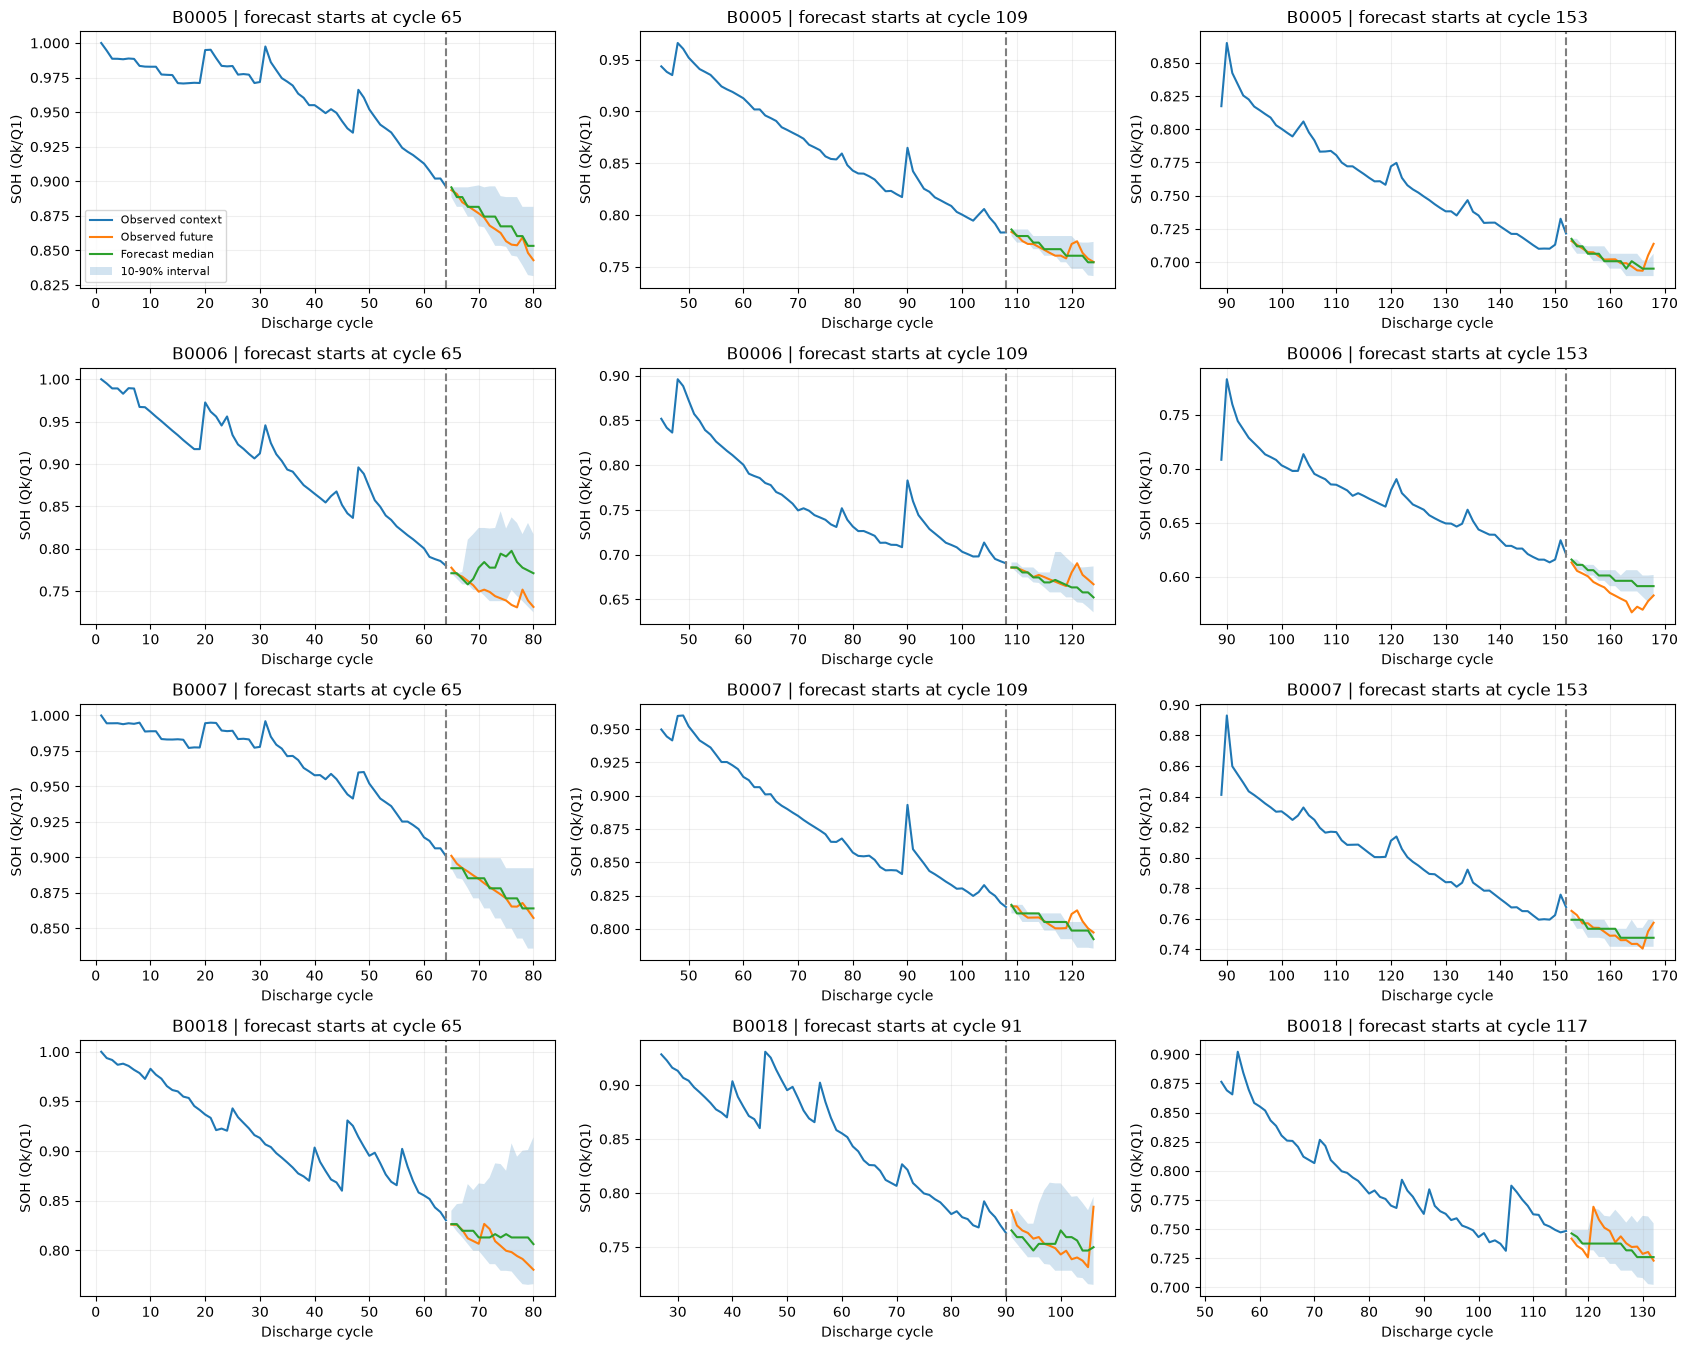

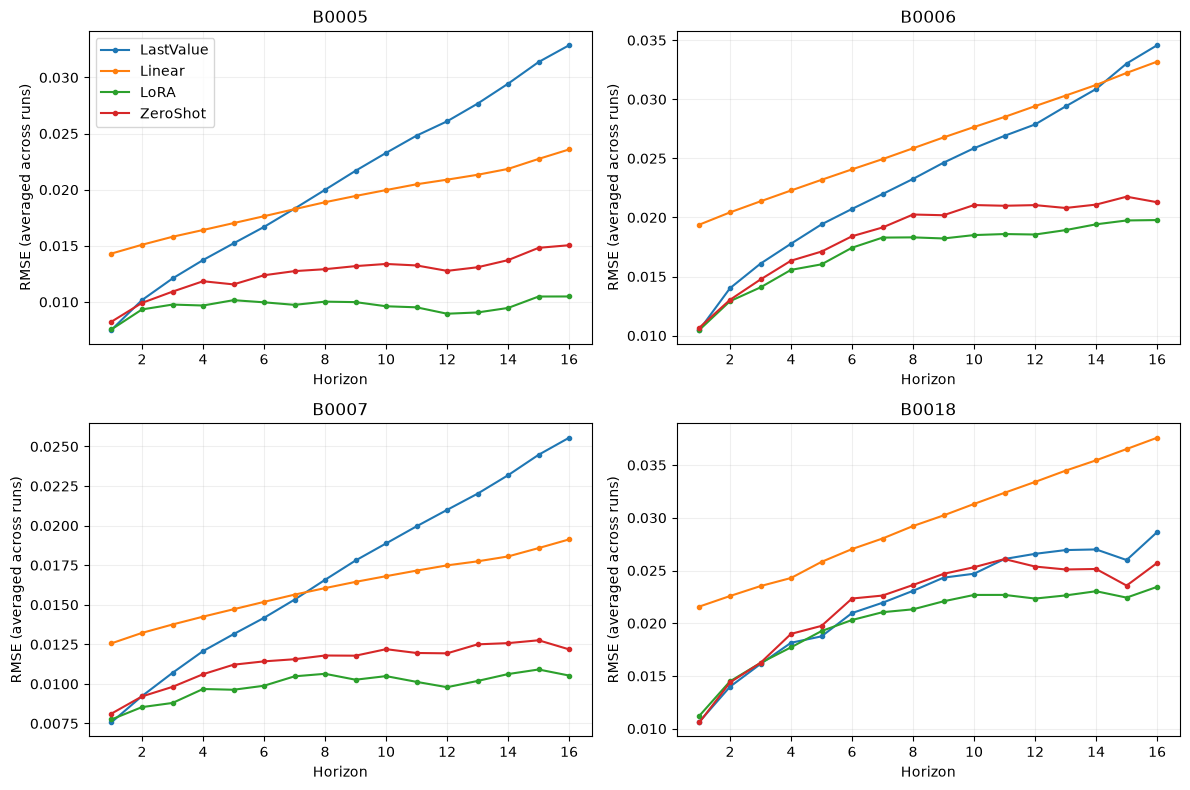

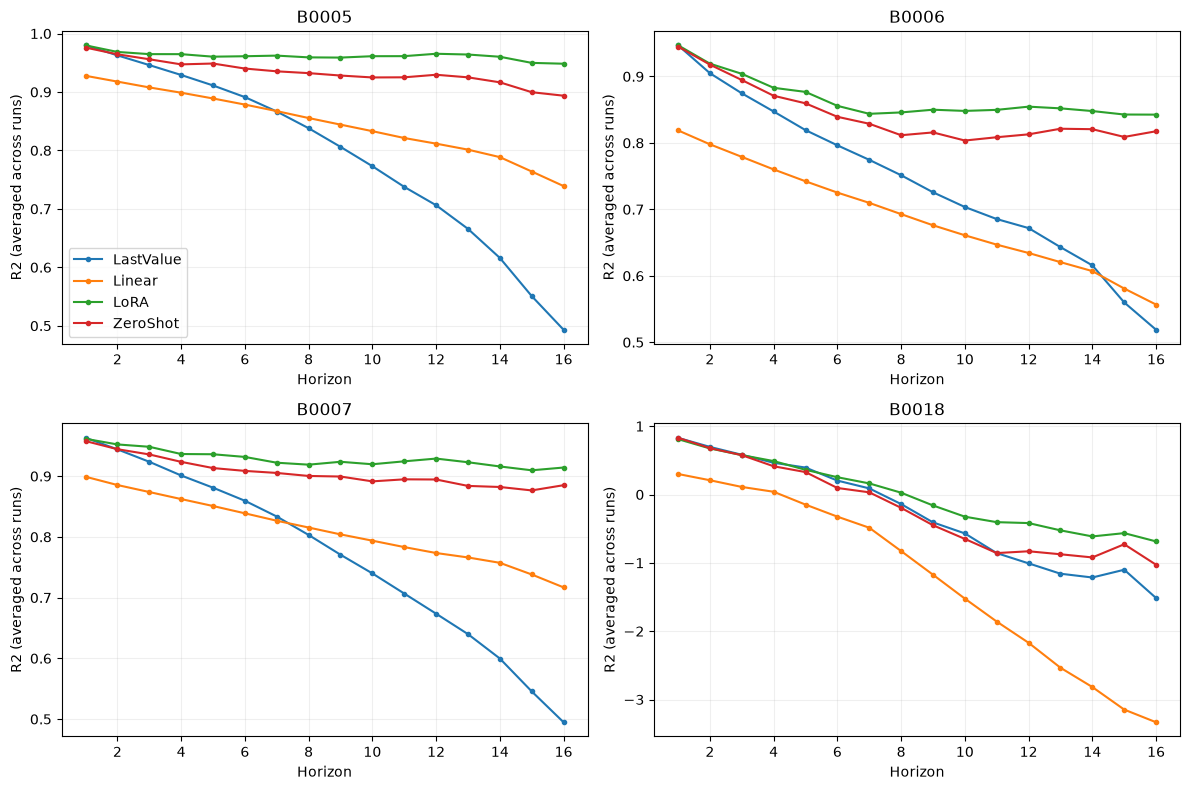

In [6]:
forecast_grid(CHECKPOINT_RUN)
plt.show()
horizon_comparison(ZERO_RUN, CHECKPOINT_RUN)
plt.show()
horizon_comparison(ZERO_EVAL, CHECKPOINT_EVAL, metric="r2")
plt.show()

## 저장·재현 확인과 해석 범위

선택한 adapter를 재로딩했을 때 validation의 원시 sample 배열이 저장 시점과 완전히 일치하는지 검사합니다. 아래 파일에는 그 결과와 모든 test 예측 전 확정한 선택 기록이 있습니다.

학습 seed는 하나입니다. Step 0을 선택하면 미학습 모델이며, 100을 선택하면 이번 탐색 상한에서의 선택입니다. 세 검증 난수와 겹치는 window가 새 배터리 사례를 추가하지는 않습니다. 이 네 배터리를 이미 살펴봤기 때문에 독립적인 새 벤치마크라고 해석하지 않습니다.

In [7]:
replay_checks = pd.read_json(CHECKPOINT_RUN / "checkpoint_replay.json")
display(replay_checks.reindex(columns=["test_battery", "selected_step", "validation_arrays_identical", "validation_arrays_checked", "macro_crps_delta"]))
if "replay_acceptance" in manifest:
    display(manifest["replay_acceptance"])
    print("Sample equality was not mandatory in this evaluation; see the report for replay differences and the recorded pre-test acceptance rule.")
frozen = json.loads((CHECKPOINT_RUN / "selection_frozen.json").read_text(encoding="utf-8"))
print("Choices frozen before test forecasting:", frozen["frozen_at"])
print("No full-data refit:", all(not fold["refit_full_data"] for fold in manifest["folds"]))

,test_battery,selected_step,validation_arrays_identical,validation_arrays_checked,macro_crps_delta
0,B0005,100,9,9,0
1,B0006,90,9,9,0
2,B0007,90,9,9,0
3,B0018,80,9,9,0


{'adapter_tensors': 'exact',
 'samples': 'differences recorded',
 'max_abs_macro_crps_delta': 1e-05,
 'selection_changed': False}

Sample equality was not mandatory in this evaluation; see the report for replay differences and the recorded pre-test acceptance rule.
Choices frozen before test forecasting: 2026-09-30T02:34:39.902438+00:00
No full-data refit: True


## 03 갈무리: 기존 LoRA와 EOS loss 제외 비교

아래 결과는 앞의 기존 LoRA 실행과 구분되는 **2026-09-29 고정 진단**입니다. 원본 LoRA는 `20260923T063628Z_lora_2df6cb`입니다. EOS 제외 모델은 같은 데이터·초기화·학습률·선택 epoch·업데이트 수를 사용하되 마지막 출력 EOS label의 loss만 제외했습니다. 입력 EOS는 유지하고, 예측 16개 토큰의 loss 가중치도 유지했습니다. 출력 clipping은 하지 않았습니다.

네 fold, 학습 seed 42 하나, 추론 seed 42/43/44를 사용했습니다. Test 결과로 checkpoint를 선택하지는 않았지만, 이미 관찰한 배터리에 대한 사후 원인 진단이므로 새로운 독립 성능 검증은 아닙니다. 비율 열 `above2_rate`, `coverage80`은 0~1 단위입니다.

In [8]:
DIAGNOSIS = PROJECT_ROOT / "results" / "diagnostics" / "20260929"
DIAGNOSIS_EVAL = export_diagnosis(PROJECT_ROOT, DIAGNOSIS)
diagnostic_metrics = pd.read_csv(DIAGNOSIS_EVAL / "seed_confirmation" / "metrics.csv")
keys = ["model", "battery", "inference_seed"]
assert len(diagnostic_metrics) == 36 and not diagnostic_metrics.duplicated(keys).any()
assert set(diagnostic_metrics["inference_seed"]) == {42, 43, 44}
score_columns = ["median_rmse", "median_r2", "mean_rmse", "mean_r2", "crps", "above2_rate", "coverage80"]
# First average inference seeds, then give the four batteries equal weight.
diagnostic_battery = diagnostic_metrics.groupby(["model", "battery"])[score_columns].mean()
diagnostic_macro = diagnostic_battery.groupby(level="model").mean()
print("Fixed snapshot: 20260929; original XPU runs + EOS-loss ablation; training seed 42")
model_order = ["zero", "original_lora", "without_eos"]
display(diagnostic_macro.loc[model_order].round(6))
median_by_battery = diagnostic_battery["median_rmse"].unstack("model")[model_order]
median_by_battery["without_eos_vs_zero_error_change_pct"] = (
    median_by_battery["without_eos"] / median_by_battery["zero"] - 1
) * 100
display(median_by_battery.round(6))
display(diagnostic_battery["median_r2"].unstack("model")[model_order].round(6))
display(diagnostic_battery["mean_r2"].unstack("model")[model_order].round(6))
print("Error change: negative is better. Inference repetitions are not training repetitions.")

Fixed snapshot: 20260929; original XPU runs + EOS-loss ablation; training seed 42


,median_rmse,median_r2,mean_rmse,mean_r2,crps,above2_rate,coverage80
model,,,,,,,
zero,0.016307,0.676844,0.018540,0.616669,0.008769,0.000063,0.803182
original_lora,0.016176,0.668538,0.294040,-65.167624,0.017684,0.016753,0.812043
without_eos,0.014894,0.731631,0.015011,0.732641,0.007552,0.000008,0.744644


model,zero,original_lora,without_eos,without_eos_vs_zero_error_change_pct
battery,,,,
B0005,0.012601,0.013148,0.010545,-16.317528
B0006,0.018900,0.019232,0.019046,0.771797
B0007,0.011423,0.009454,0.009813,-14.092483
B0018,0.022303,0.022868,0.020174,-9.545490


model,zero,original_lora,without_eos
battery,,,
B0005,0.937543,0.932022,0.956277
B0006,0.845382,0.839919,0.842996
B0007,0.910154,0.938452,0.933693
B0018,0.014299,-0.036239,0.193560


model,zero,original_lora,without_eos
battery,,,
B0005,0.923080,-117.917826,0.955463
B0006,0.822900,-11.954696,0.844949
B0007,0.800628,-37.385572,0.924309
B0018,-0.079932,-93.412401,0.205844


Error change: negative is better. Inference repetitions are not training repetitions.


### 분리 검증으로 확인한 원인

- **EOS 학습 항:** 이 항만 제외했을 때 네 배터리 모두 평균 예측 RMSE와 CRPS가 회복됐습니다. macro 중앙값 RMSE는 zero-shot보다 8.66% 감소했습니다.
- **재학습 업데이트 증가:** B0005에서 같은 full-data 학습의 81회와 135회를 비교하면 평균 예측 RMSE가 `0.041309 → 0.551199`로 악화됐습니다. epoch를 그대로 옮기면 데이터가 늘어난 만큼 업데이트도 늘어납니다.
- **학습률:** B0005에서 학습률만 `1e-4 → 3e-5`로 낮추어도 폭주가 줄었습니다. 나머지 배터리의 학습률 효과까지 분리한 것은 아닙니다.
- **추론 구현:** B0005 앞 32개 window에서 PEFT generate wrapper를 우회해도 결과가 같고, 같은 checkpoint의 FP32 추론에서도 폭주했습니다. FP32 재학습이나 cache 영향까지 배제한 것은 아닙니다.

다음 표는 **B0005 전체 window, 추론 seed 42 하나**의 비교입니다. 위 세 추론 seed 평균과 구분합니다. `selection_prefix`는 데이터와 업데이트 수가 함께 바뀐 보조 실험이므로 한 요인 비교 표에서 제외했습니다.

,variant,checkpoint,steps,median_rmse,median_r2,mean_rmse,mean_r2,crps,above2_rate
0,baseline,matched_updates,81,0.011743,0.945783,0.041309,0.329035,0.007221,0.001032
1,baseline,final,135,0.013220,0.931285,0.551199,-118.460420,0.032993,0.035604
2,lower_lr,final,135,0.012229,0.941196,0.017002,0.886345,0.006763,0.000126
3,without_eos,final,135,0.010525,0.956440,0.010318,0.958138,0.005643,0.000035


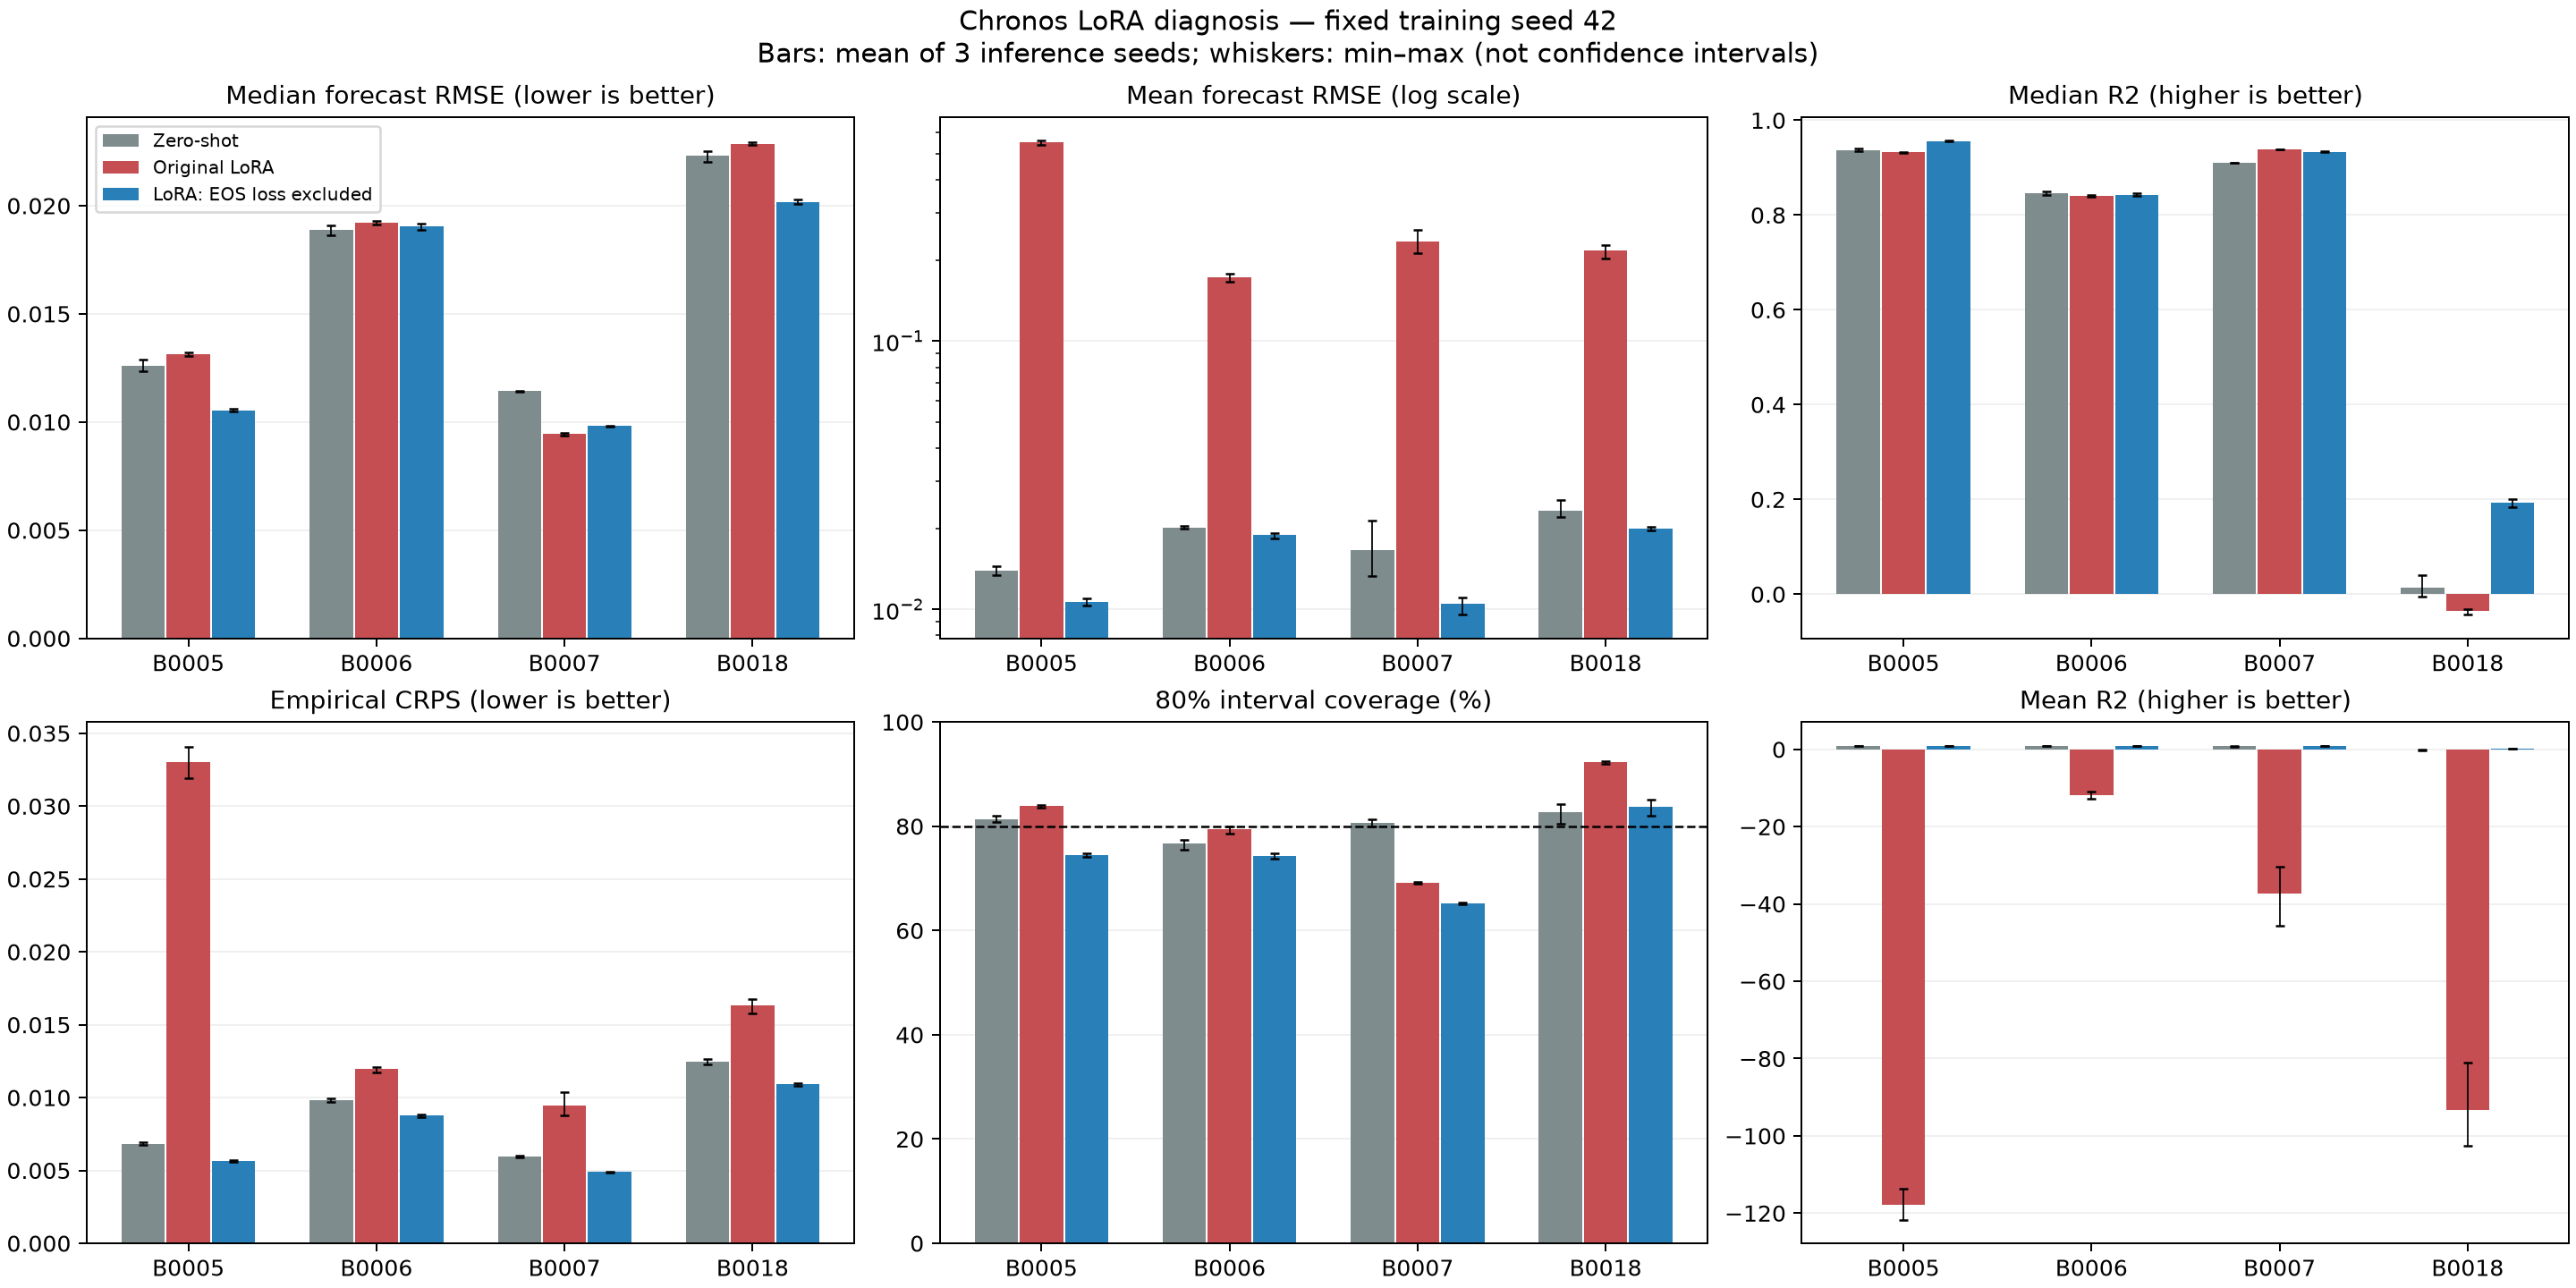

In [9]:
training_controls = pd.read_csv(DIAGNOSIS_EVAL / "training" / "training_controls.csv")
display(training_controls.loc[
    training_controls["variant"] != "selection_prefix",
    ["variant", "checkpoint", "steps", "median_rmse", "median_r2", "mean_rmse", "mean_r2", "crps", "above2_rate"],
].round(6))
from IPython.display import Image
display(Image(filename=str(DIAGNOSIS / "diagnosis_comparison.png"), width=1000))

### 03의 결론과 남은 문제

현재 LoRA의 문제를 단순히 데이터 부족이나 rank 부족으로 결론내릴 수 없습니다. **EOS 목적함수와 학습량의 영향**을 확인했고, EOS 제외 LoRA를 04의 비교 후보로 남깁니다.

- B0006 중앙값 RMSE는 zero-shot보다 약 0.77% 나쁩니다. B0007 중앙값은 기존 LoRA보다 나빠졌습니다.
- EOS 제외의 80% 구간 포함률은 macro 약 74.46%, B0007 약 65.29%로 낮아졌습니다. 정확도 개선과 불확실성 보정은 별도 문제입니다.
- 드문 극단 sample이 여전히 남고, 학습 난수 반복은 아직 하지 않았습니다.
- `cuda-fullft`의 KL 정규화·검증 정책 실험은 다른 프로토콜입니다. 이번 EOS 제외 결과와 개선율을 직접 비교하지 않습니다.

04에서는 같은 base model·장치·분할·EOS 정책으로 zero-shot / LoRA / Full FT를 비교하고, 학습률과 checkpoint는 훈련 배터리 내부 검증으로 고릅니다. 검증한 checkpoint를 그대로 평가하며 별도 refit은 기본 비교에 넣지 않습니다. 현재 진단 점수는 참고값이고, 그 프로토콜에 맞춘 LoRA 대조군을 다시 평가해야 합니다. **04 구현·학습은 이번 갈무리에 포함하지 않았습니다.**

[02·03 정리와 04 비교 조건](../docs/02_03_closeout.md) · [상세 진단 보고서와 원시 결과](../results/diagnostics/20260929/diagnosis.md)